# Performance Analysis of Tree-Based Regressors in Predicting Protein Tertiary Structure Deviation
Using supervised regression, this project aims to predict the tertiary structural deviation of proteins based on their physicochemical and geometric properties. By analyzing features such as solvent-exposed surface area, molecular properties, and structural constraints, the model will learn relationships between these descriptors and the Root Mean Square Deviation (RMSD) of protein structures.

The objective is to evaluate how effectively machine learning can estimate structural deviation from these features, using established regression metrics to assess prediction performance. 

## Dataset Citation

Rana, P. (2013). *Physicochemical Properties of Protein Tertiary Structure*. UCI Machine Learning Repository. https://doi.org/10.24432/C5QW3H

### BibTeX

```bibtex
@misc{rana2013protein,
  author       = {Rana, Prashant},
  title        = {Physicochemical Properties of Protein Tertiary Structure},
  year         = {2013},
  publisher    = {UCI Machine Learning Repository},
  doi          = {10.24432/C5QW3H},
  url          = {https://doi.org/10.24432/C5QW3H}
}
```

The features represent different structural properties:

- F1: Total surface area

- F2: Non-polar exposed area

- F3: Fractional area of exposed non-polar residues

- F4: Fractional area of the exposed non-polar part of a residue

- F5: Molecular-mass-weighted exposed area

- F6: Average deviation from the standard exposed area of a residue

- F7: Euclidean distance

- F8: Secondary structure penalty

- F9: Spatial distribution constraints (N, K values)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("./protein.csv")
df.head()

,RMSD,F1,F2,F3,F4,F5,F6,F7,F8,F9
0,17.284,13558.30,4305.35,0.31754,162.1730,1.872791e+06,215.3590,4287.87,102,27.0302
1,6.021,6191.96,1623.16,0.26213,53.3894,8.034467e+05,87.2024,3328.91,39,38.5468
2,9.275,7725.98,1726.28,0.22343,67.2887,1.075648e+06,81.7913,2981.04,29,38.8119
3,15.851,8424.58,2368.25,0.28111,67.8325,1.210472e+06,109.4390,3248.22,70,39.0651
4,7.962,7460.84,1736.94,0.23280,52.4123,1.021020e+06,94.5234,2814.42,41,39.9147


## Exploratory Data Analysis
For feature selection and redundancy elimination, exploratory data analysis is performed on the dataset. 

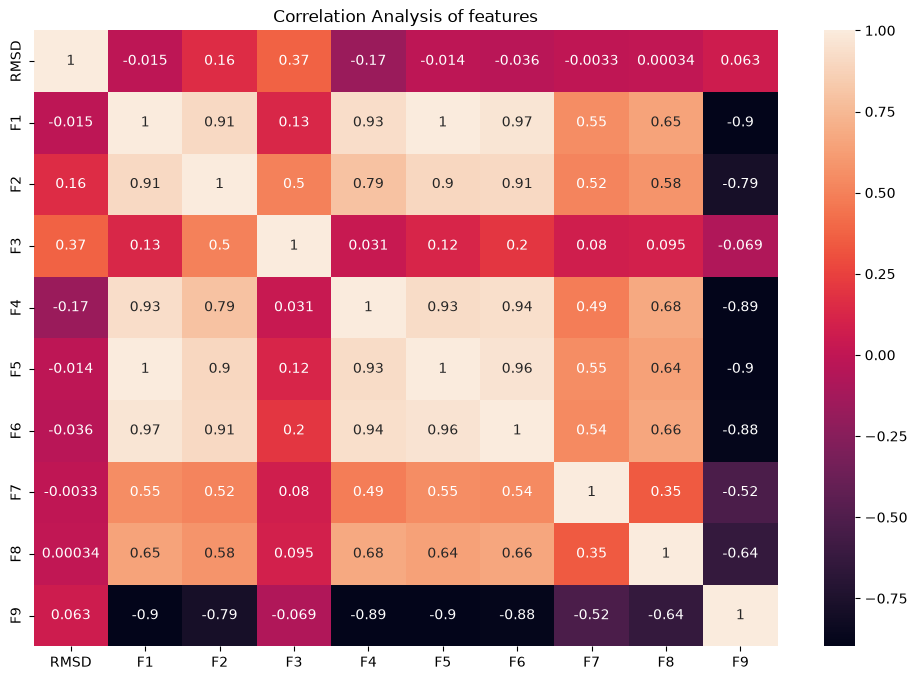

In [3]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))
plt.title("Correlation Analysis of features")
sns.heatmap(corr,annot=True)
plt.show()

- The correlation analysis reveals that most input features exhibit **weak linear relationships** with RMSD, with F3 showing the strongest positive correlation (r ≈ 0.374). This suggests that the target variable may be poorly explained by simple linear relationships alone, motivating further investigation using **nonlinear regression models.**
- Additionally, **strong correlations** (|r| > 0.9) were observed **among several input features**, indicating **potential redundancy**. To reduce **multicollinearity**, F1, F5, and F6 were excluded from the feature set, retaining F2 and F4 from the highly correlated group.

In [6]:
selected_features =  ["F2", "F3", "F4", "F7", "F8", "F9"]
X = df[selected_features]
y = df["RMSD"]

#### Statistical Metadata

In [8]:
X.info()
X.describe()

<class 'pandas.DataFrame'>
RangeIndex: 45730 entries, 0 to 45729
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   F2      45730 non-null  float64
 1   F3      45730 non-null  float64
 2   F4      45730 non-null  float64
 3   F7      45730 non-null  float64
 4   F8      45730 non-null  int64  
 5   F9      45730 non-null  float64
dtypes: float64(5), int64(1)
memory usage: 2.1 MB


,F2,F3,F4,F7,F8,F9
count,45730.000000,45730.000000,45730.000000,45730.000000,45730.000000,45730.000000
mean,3017.367175,0.302392,103.492433,3989.755990,69.975071,34.523664
std,1464.324663,0.062886,55.424985,1993.574575,56.493443,5.979755
min,403.500000,0.092500,10.310100,0.000000,0.000000,15.228000
25%,1979.045000,0.258740,63.563900,3165.322500,31.000000,30.424725
50%,2668.155000,0.300150,87.740800,3840.170000,54.000000,35.299300
75%,3786.410000,0.342890,133.646750,4644.192500,91.000000,38.870800
max,15312.000000,0.577690,369.317000,105948.170000,350.000000,55.300900


In [10]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [16]:
METRICS=[]

## Model Selection: Random Forest Regressor

The correlation analysis revealed that most input features exhibit weak linear relationships with RMSD, suggesting that the relationship between physicochemical descriptors and protein structural deviation may involve nonlinear patterns. Therefore, a Random Forest Regressor was selected for its ability to capture nonlinear relationships and feature interactions through an ensemble of decision trees. It also requires no feature scaling and offers flexibility in controlling tree complexity. Its performance will be evaluated using MAE, RMSE, and R².

- Due to hardware constraints and the computational cost of five-fold cross-validation, manual experiments will be conducted to evaluate different Random Forest hyperparameter configurations. Key parameters, including the number of trees, the number of features considered at each split, the minimum samples per leaf, and the maximum tree depth, will be varied individually. The resulting models will be compared using MAE, RMSE, and R² to identify a suitable configuration.

In [17]:
from sklearn.ensemble import RandomForestRegressor

experiments = [
    # 100 trees
    {"name": "100 trees", "n_estimators": 100},
    {"name": "100 trees, depth=10", "n_estimators": 100, "max_depth": 10},
    {"name": "100 trees, depth=15", "n_estimators": 100, "max_depth": 15},

    # 200 trees
    {"name": "200 trees", "n_estimators": 200},
    {"name": "200 trees, depth=10", "n_estimators": 200, "max_depth": 10},
    {"name": "200 trees, depth=15", "n_estimators": 200, "max_depth": 15},

    # 400 trees
    {"name": "400 trees", "n_estimators": 400},
    {"name": "400 trees, depth=10", "n_estimators": 400, "max_depth": 10},
    {"name": "400 trees, depth=12", "n_estimators": 400, "max_depth": 12},
    {"name": "400 trees, depth=15", "n_estimators": 400, "max_depth": 15},

    # 600 trees
    {"name": "600 trees", "n_estimators": 600},
    {"name": "600 trees, depth=10", "n_estimators": 600, "max_depth": 10},
    {"name": "600 trees, depth=12", "n_estimators": 600, "max_depth": 12},
    {"name": "600 trees, depth=15", "n_estimators": 600, "max_depth": 15},

    # 800 trees
    {"name": "800 trees", "n_estimators": 800},
    {"name": "800 trees, depth=10", "n_estimators": 800, "max_depth": 10},
    {"name": "800 trees, depth=12", "n_estimators": 800, "max_depth": 12},
    {"name": "800 trees, depth=15", "n_estimators": 800, "max_depth": 15},

    # 1000 trees
    {"name": "1000 trees", "n_estimators": 1000},
    {"name": "1000 trees, depth=10", "n_estimators": 1000, "max_depth": 10},
    {"name": "1000 trees, depth=12", "n_estimators": 1000, "max_depth": 12},
    {"name": "1000 trees, depth=15", "n_estimators": 1000, "max_depth": 15},

    
]
results = []

for exp in experiments:
    name = exp["name"]
    params = {k: v for k, v in exp.items() if k != "name"}

    print(f"Running: {name}", flush=True)

    rf = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rmsd_range = y_test.max() - y_test.min()
    nmae = (mae / rmsd_range) * 100

    within_1 = (np.abs(y_test - y_pred) <= 1).mean() * 100
    within_2 = (np.abs(y_test - y_pred) <= 2).mean() * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "NMAE (%)": nmae,
        "Within ±1 (%)": within_1,
        "Within ±2 (%)": within_2
    })

    del rf

results_df = pd.DataFrame(results)
display(results_df.round(4))
METRICS.append(results_df)

Running: 100 trees
Running: 100 trees, depth=10
Running: 100 trees, depth=15
Running: 200 trees
Running: 200 trees, depth=10
Running: 200 trees, depth=15
Running: 400 trees
Running: 400 trees, depth=10
Running: 400 trees, depth=12
Running: 400 trees, depth=15
Running: 600 trees
Running: 600 trees, depth=10
Running: 600 trees, depth=12
Running: 600 trees, depth=15
Running: 800 trees
Running: 800 trees, depth=10
Running: 800 trees, depth=12
Running: 800 trees, depth=15
Running: 1000 trees
Running: 1000 trees, depth=10
Running: 1000 trees, depth=12
Running: 1000 trees, depth=15


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,100 trees,2.5319,3.6908,0.6380,12.0583,38.8038,55.9480
1,"100 trees, depth=10",3.2447,4.2584,0.5181,15.4531,23.1795,42.0621
2,"100 trees, depth=15",2.7157,3.8205,0.6121,12.9336,34.0149,52.7225
3,200 trees,2.5225,3.6748,0.6412,12.0135,38.8148,56.1120
4,"200 trees, depth=10",3.2389,4.2511,0.5198,15.4258,23.0374,42.0293
5,"200 trees, depth=15",2.7088,3.8055,0.6152,12.9007,33.8399,52.9193
6,400 trees,2.5195,3.6667,0.6427,11.9991,38.7929,55.9917
7,"400 trees, depth=10",3.2375,4.2477,0.5206,15.4191,23.0374,42.0840
8,"400 trees, depth=12",2.9598,4.0044,0.5739,14.0962,27.8482,47.4415
9,"400 trees, depth=15",2.7049,3.7968,0.6169,12.8825,33.7853,52.7116


- Random Forest was evaluated through experiments varying the number of trees and hyperparameters such as maximum tree depth. The results showed that increasing the tree count gradually improved the baseline model, while restricting tree depth generally reduced predictive performance. The best-performing configuration among these experiments used 1,000 trees with unrestricted depth, achieving a final MAE of **2.5172**, RMSE of **3.6637**, and R² of **0.6433**. These results indicate that unrestricted tree depth was more effective for this dataset, although improvements from increasing the tree count became progressively smaller.

## Model Selection: XGBoost Regressor

XGBoost was selected as an additional regression model to compare its performance with the Random Forest Regressor. It uses gradient boosting to build decision trees sequentially, with each successive tree aiming to reduce the errors of the existing ensemble. Its ability to capture nonlinear relationships and feature interactions makes it suitable for predicting protein structural deviation from physicochemical descriptors. Its performance will be evaluated using MAE, RMSE, and R².

In [18]:
from xgboost import XGBRegressor

experiments = [
    # Initial experiments: 100 trees
    {"name": "100 trees", "n_estimators": 100},
    {"name": "100 trees, depth=3", "n_estimators": 100, "max_depth": 3},
    {"name": "100 trees, lr=0.05", "n_estimators": 100, "learning_rate": 0.05},

    # Initial experiments: 200 trees
    {"name": "200 trees", "n_estimators": 200},
    {"name": "200 trees, depth=3", "n_estimators": 200, "max_depth": 3},
    {"name": "200 trees, lr=0.05", "n_estimators": 200, "learning_rate": 0.05},

    # Initial experiments: 400 trees
    {"name": "400 trees", "n_estimators": 400},
    {"name": "400 trees, depth=3", "n_estimators": 400, "max_depth": 3},
    {"name": "400 trees, lr=0.05", "n_estimators": 400, "learning_rate": 0.05},

    # Promising 400-tree configurations
    {"name": "400 trees, depth=8", "n_estimators": 400, "max_depth": 8},
    {"name": "400 trees, depth=10", "n_estimators": 400, "max_depth": 10},
    {"name": "400 trees, depth=12", "n_estimators": 400, "max_depth": 12},
    {"name": "400 trees, lr=0.2", "n_estimators": 400, "learning_rate": 0.2},
    {"name": "400 trees, depth=8, lr=0.1",
     "n_estimators": 400, "max_depth": 8, "learning_rate": 0.1},

    # Explore 800 trees
    {"name": "800 trees", "n_estimators": 800},
    {"name": "800 trees, depth=10", "n_estimators": 800, "max_depth": 10},
    {"name": "800 trees, depth=12", "n_estimators": 800, "max_depth": 12},
    {"name": "800 trees, depth=15", "n_estimators": 800, "max_depth": 15},

    # Explore learning rates with 800 trees
    {"name": "800 trees, depth=10, lr=0.2",
     "n_estimators": 800, "max_depth": 10, "learning_rate": 0.2},
    {"name": "800 trees, depth=12, lr=0.1",
     "n_estimators": 800, "max_depth": 12, "learning_rate": 0.1},
    {"name": "800 trees, depth=12, lr=0.2",
     "n_estimators": 800, "max_depth": 12, "learning_rate": 0.2},

    # Explore 1000 trees
    {"name": "1000 trees, depth=10",
     "n_estimators": 1000, "max_depth": 10},
    {"name": "1000 trees, depth=12",
     "n_estimators": 1000, "max_depth": 12},
]
results = []

for exp in experiments:
    name = exp["name"]
    params = {k: v for k, v in exp.items() if k != "name"}

    print(f"Running: {name}", flush=True)

    xgb = XGBRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rmsd_range = y_test.max() - y_test.min()
    nmae = (mae / rmsd_range) * 100

    within_1 = (np.abs(y_test - y_pred) <= 1).mean() * 100
    within_2 = (np.abs(y_test - y_pred) <= 2).mean() * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "NMAE (%)": nmae,
        "Within ±1 (%)": within_1,
        "Within ±2 (%)": within_2
    })

    del xgb

results_df = pd.DataFrame(results)
display(results_df.round(4))
METRICS.append(results_df)

Running: 100 trees
Running: 100 trees, depth=3
Running: 100 trees, lr=0.05
Running: 200 trees
Running: 200 trees, depth=3
Running: 200 trees, lr=0.05
Running: 400 trees
Running: 400 trees, depth=3
Running: 400 trees, lr=0.05
Running: 400 trees, depth=8
Running: 400 trees, depth=10
Running: 400 trees, depth=12
Running: 400 trees, lr=0.2
Running: 400 trees, depth=8, lr=0.1
Running: 800 trees
Running: 800 trees, depth=10
Running: 800 trees, depth=12
Running: 800 trees, depth=15
Running: 800 trees, depth=10, lr=0.2
Running: 800 trees, depth=12, lr=0.1
Running: 800 trees, depth=12, lr=0.2
Running: 1000 trees, depth=10
Running: 1000 trees, depth=12


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,100 trees,2.9615,4.0375,0.5668,14.1046,28.7885,47.9663
1,"100 trees, depth=3",3.5506,4.5487,0.4502,16.9101,19.5386,36.9779
2,"100 trees, lr=0.05",3.5044,4.4683,0.4695,16.6900,18.4671,37.1201
3,200 trees,2.8393,3.9402,0.5874,13.5223,31.0300,50.7326
4,"200 trees, depth=3",3.3778,4.3893,0.4881,16.0872,22.0096,39.7332
5,"200 trees, lr=0.05",3.2082,4.2213,0.5265,15.2791,23.6606,43.0133
6,400 trees,2.7685,3.9066,0.5945,13.1853,32.8122,52.6350
7,"400 trees, depth=3",3.2133,4.2394,0.5224,15.3038,24.1526,42.4010
8,"400 trees, lr=0.05",3.0168,4.0660,0.5607,14.3678,27.7936,46.6652
9,"400 trees, depth=8",2.6753,3.9174,0.5922,12.7415,37.7542,55.4669


- XGBoost was evaluated through experiments varying the number of trees, maximum tree depth, and learning rate. The results showed that increasing model complexity and adjusting the learning rate improved predictive performance, although the effects varied across configurations. The best overall regression performance was achieved by the 800-tree model with a maximum depth of 12 and a learning rate of 0.1, obtaining a final MAE of **2.4708**, RMSE of **3.7517**, and R² of **0.6260**. The 800-tree model with a depth of 15 achieved the highest proportion of predictions within ±1 and ±2 RMSD units, highlighting the trade-off between overall regression accuracy and prediction tolerance.

## Model Selection: Extra Trees Regressor

Since the Random Forest Regressor performed better than XGBoost in the previous experiments, Extra Trees Regressor was selected to investigate whether introducing greater randomness into tree construction could further improve predictive performance. Like Random Forest, Extra Trees combines predictions from multiple decision trees, but introduces additional randomness when selecting split thresholds. This provides an opportunity to explore whether a more randomized tree ensemble can capture useful patterns in the physicochemical descriptors and improve RMSD prediction. Experiments will evaluate different numbers of trees and maximum tree depths, with performance compared using MAE, RMSE, R², NMAE, and prediction accuracy within ±1 and ±2 RMSD units.

In [19]:
from sklearn.ensemble import ExtraTreesRegressor

experiments = [
    # 100 trees
    {"name": "100 trees", "n_estimators": 100},
    {"name": "100 trees, depth=10", "n_estimators": 100, "max_depth": 10},
    {"name": "100 trees, depth=15", "n_estimators": 100, "max_depth": 15},

    # 200 trees
    {"name": "200 trees", "n_estimators": 200},
    {"name": "200 trees, depth=10", "n_estimators": 200, "max_depth": 10},
    {"name": "200 trees, depth=15", "n_estimators": 200, "max_depth": 15},

    # 400 trees
    {"name": "400 trees", "n_estimators": 400},
    {"name": "400 trees, depth=10", "n_estimators": 400, "max_depth": 10},
    {"name": "400 trees, depth=12", "n_estimators": 400, "max_depth": 12},
    {"name": "400 trees, depth=15", "n_estimators": 400, "max_depth": 15},

    # 600 trees
    {"name": "600 trees", "n_estimators": 600},
    {"name": "600 trees, depth=10", "n_estimators": 600, "max_depth": 10},
    {"name": "600 trees, depth=12", "n_estimators": 600, "max_depth": 12},
    {"name": "600 trees, depth=15", "n_estimators": 600, "max_depth": 15},

    # 800 trees
    {"name": "800 trees", "n_estimators": 800},
    {"name": "800 trees, depth=10", "n_estimators": 800, "max_depth": 10},
    {"name": "800 trees, depth=12", "n_estimators": 800, "max_depth": 12},
    {"name": "800 trees, depth=15", "n_estimators": 800, "max_depth": 15},

    # 1000 trees
    {"name": "1000 trees", "n_estimators": 1000},
    {"name": "1000 trees, depth=10", "n_estimators": 1000, "max_depth": 10},
    {"name": "1000 trees, depth=12", "n_estimators": 1000, "max_depth": 12},
    {"name": "1000 trees, depth=15", "n_estimators": 1000, "max_depth": 15},
]

results = []

for exp in experiments:
    name = exp["name"]
    params = {k: v for k, v in exp.items() if k != "name"}

    print(f"Running: {name}", flush=True)

    et = ExtraTreesRegressor(
        **params,
        random_state=42,
        n_jobs=-1
    )

    et.fit(X_train, y_train)
    y_pred = et.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rmsd_range = y_test.max() - y_test.min()
    nmae = (mae / rmsd_range) * 100

    within_1 = (np.abs(y_test - y_pred) <= 1).mean() * 100
    within_2 = (np.abs(y_test - y_pred) <= 2).mean() * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "NMAE (%)": nmae,
        "Within ±1 (%)": within_1,
        "Within ±2 (%)": within_2
    })

    del et

results_df = pd.DataFrame(results)
display(results_df.round(4))
METRICS.append(results_df)

Running: 100 trees
Running: 100 trees, depth=10
Running: 100 trees, depth=15
Running: 200 trees
Running: 200 trees, depth=10
Running: 200 trees, depth=15
Running: 400 trees
Running: 400 trees, depth=10
Running: 400 trees, depth=12
Running: 400 trees, depth=15
Running: 600 trees
Running: 600 trees, depth=10
Running: 600 trees, depth=12
Running: 600 trees, depth=15
Running: 800 trees
Running: 800 trees, depth=10
Running: 800 trees, depth=12
Running: 800 trees, depth=15
Running: 1000 trees
Running: 1000 trees, depth=10
Running: 1000 trees, depth=12
Running: 1000 trees, depth=15


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,100 trees,2.4108,3.5655,0.6622,11.4816,41.6904,56.9320
1,"100 trees, depth=10",3.9098,4.7559,0.3990,18.6206,13.1424,28.0778
2,"100 trees, depth=15",3.1595,4.0863,0.5563,15.0472,23.1139,41.6904
3,200 trees,2.4056,3.5578,0.6637,11.4568,41.6576,57.2163
4,"200 trees, depth=10",3.9007,4.7489,0.4007,18.5772,13.1752,28.2856
5,"200 trees, depth=15",3.1547,4.0808,0.5575,15.0246,23.1905,41.5373
6,400 trees,2.4017,3.5499,0.6651,11.4385,41.7122,57.3147
7,"400 trees, depth=10",3.8954,4.7428,0.4023,18.5521,13.3610,28.4933
8,"400 trees, depth=12",3.5869,4.4609,0.4712,17.0829,16.7833,33.8071
9,"400 trees, depth=15",3.1425,4.0679,0.5603,14.9666,23.1249,41.9200


- Extra Trees Regressor was evaluated through experiments varying the number of trees and maximum tree depth. The results showed that increasing the number of trees gradually improved predictive performance, while restricting tree depth significantly reduced accuracy. The best overall regression performance was achieved by the 1000-tree model with unrestricted depth, obtaining a final MAE of **2.3997**, RMSE of **3.5471**, and R² of **0.6657**. However, the improvements became marginal beyond 400 trees, suggesting diminishing returns from increasing ensemble size. These results indicate that a more randomized tree ensemble achieved better predictive performance than the previously evaluated Random Forest and XGBoost models.

## Observation
- The Random Forest Regressor outperformed the XGBoost Regressor, suggesting that a randomized tree-based approach might be better suited to the given dataset.
- This hypothesis was further supported by the Extra Trees Regressor, which achieved better predictive performance than both models.
- Based on these results, additional experiments were conducted to investigate whether introducing further randomness through feature selection and bootstrap sampling could improve the Extra Trees Regressor's performance.

In [20]:
from sklearn.ensemble import ExtraTreesRegressor

experiments = [
    # Baseline
    {"name": "Baseline, 400 trees", "max_features": 1.0},

    # Increase feature randomness
    {"name": "400 trees, max_features=0.8", "max_features": 0.8},
    {"name": "400 trees, max_features=0.7", "max_features": 0.7},
    {"name": "400 trees, max_features=0.5", "max_features": 0.5},
    {"name": "400 trees, max_features=sqrt", "max_features": "sqrt"},
    {"name": "400 trees, max_features=log2", "max_features": "log2"},

    # Introduce bootstrap sampling
    {"name": "400 trees, bootstrap 100%",
     "max_features": 1.0, "bootstrap": True, "max_samples": 1.0},

    {"name": "400 trees, bootstrap 80%",
     "max_features": 1.0, "bootstrap": True, "max_samples": 0.8},

    {"name": "400 trees, bootstrap 60%",
     "max_features": 1.0, "bootstrap": True, "max_samples": 0.6},

    # Combine feature randomness and bootstrap sampling
    {"name": "max_features=0.7, bootstrap 80%",
     "max_features": 0.7, "bootstrap": True, "max_samples": 0.8},

    {"name": "max_features=0.5, bootstrap 80%",
     "max_features": 0.5, "bootstrap": True, "max_samples": 0.8},

    {"name": "max_features=sqrt, bootstrap 60%",
     "max_features": "sqrt", "bootstrap": True, "max_samples": 0.6},
]

results = []

for exp in experiments:
    name = exp["name"]
    params = {k: v for k, v in exp.items() if k != "name"}

    print(f"Running: {name}", flush=True)

    et = ExtraTreesRegressor(
        n_estimators=400,
        max_depth=None,
        random_state=42,
        n_jobs=-1,
        **params
    )

    et.fit(X_train, y_train)
    y_pred = et.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    rmsd_range = y_test.max() - y_test.min()
    nmae = (mae / rmsd_range) * 100

    within_1 = (np.abs(y_test - y_pred) <= 1).mean() * 100
    within_2 = (np.abs(y_test - y_pred) <= 2).mean() * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "NMAE (%)": nmae,
        "Within ±1 (%)": within_1,
        "Within ±2 (%)": within_2
    })

    del et

results_df = pd.DataFrame(results)
display(results_df.round(4))

METRICS.append(results_df)

Running: Baseline, 400 trees
Running: 400 trees, max_features=0.8
Running: 400 trees, max_features=0.7
Running: 400 trees, max_features=0.5
Running: 400 trees, max_features=sqrt
Running: 400 trees, max_features=log2
Running: 400 trees, bootstrap 100%
Running: 400 trees, bootstrap 80%
Running: 400 trees, bootstrap 60%
Running: max_features=0.7, bootstrap 80%
Running: max_features=0.5, bootstrap 80%
Running: max_features=sqrt, bootstrap 60%


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,"Baseline, 400 trees",2.4017,3.5499,0.6651,11.4385,41.7122,57.3147
1,"400 trees, max_features=0.8",2.4243,3.5571,0.6638,11.5458,41.0999,56.8555
2,"400 trees, max_features=0.7",2.4243,3.5571,0.6638,11.5458,41.0999,56.8555
3,"400 trees, max_features=0.5",2.4533,3.5692,0.6615,11.6842,39.9082,56.0573
4,"400 trees, max_features=sqrt",2.5035,3.6079,0.6541,11.9232,38.6617,54.7452
5,"400 trees, max_features=log2",2.5035,3.6079,0.6541,11.9232,38.6617,54.7452
6,"400 trees, bootstrap 100%",2.5696,3.6360,0.6487,12.2381,36.3547,53.9580
7,"400 trees, bootstrap 80%",2.6194,3.6704,0.6420,12.4749,35.0864,52.7881
8,"400 trees, bootstrap 60%",2.6882,3.7208,0.6321,12.8026,33.3916,51.4870
9,"max_features=0.7, bootstrap 80%",2.6472,3.6843,0.6393,12.6075,34.2226,52.4273


- Increasing randomness through feature subsampling and introducing bootstrap sampling did not improve predictive performance. The baseline Extra Trees model, using all features without bootstrap sampling, achieved the best results among these experiments.

# Observations and Best-Performing Models

Based on the experiments conducted, the best-performing configurations from each tree-based model family were selected for comparison. Random Forest, XGBoost, and Extra Trees were evaluated using MAE, RMSE, R², NMAE, and the percentage of predictions falling within ±1 and ±2 RMSD units.

The results showed that Extra Trees achieved the strongest predictive performance among the evaluated tree-based approaches. Although XGBoost uses sequential boosting to correct errors made by previous trees, it did not outperform the more randomized ensemble methods in our experiments. One possible explanation is that the boosting models were more susceptible to overfitting the training data, whereas the additional randomization in Extra Trees may have helped it generalize better to the test set. However, this remains a possible explanation rather than a confirmed cause.

With these experiments completed, the following table presents the best-performing configurations identified for each tree-based model family, ranked by their R² scores. These results highlight the importance of evaluating different ensemble strategies empirically, as sequential error correction does not necessarily outperform greater randomization for every dataset.

In [29]:
model_results = {
    "Random Forest": METRICS[0].sort_values("R2", ascending=False).reset_index(drop=True),
    "XGBoost": METRICS[1].sort_values("R2", ascending=False).reset_index(drop=True),
    "Extra Trees": pd.concat(METRICS[2:4], ignore_index=True)
        .sort_values("R2", ascending=False)
        .reset_index(drop=True)
}

for model, data in model_results.items():
    print(f"\n{model}")
    display(data.head(6).round(4))


Random Forest


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,1000 trees,2.5172,3.6637,0.6433,11.9885,38.7492,56.1010
1,800 trees,2.5180,3.6641,0.6433,11.9921,38.5961,56.0901
2,600 trees,2.5185,3.6653,0.6430,11.9948,38.7929,56.0682
3,400 trees,2.5195,3.6667,0.6427,11.9991,38.7929,55.9917
4,200 trees,2.5225,3.6748,0.6412,12.0135,38.8148,56.1120
5,100 trees,2.5319,3.6908,0.6380,12.0583,38.8038,55.9480



XGBoost


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,"800 trees, depth=12, lr=0.1",2.4708,3.7517,0.6260,11.7673,43.0352,58.3424
1,"800 trees, depth=12, lr=0.2",2.4825,3.7741,0.6215,11.8233,41.9637,58.4518
2,"400 trees, depth=8, lr=0.1",2.6461,3.7760,0.6211,12.6021,35.5784,54.2532
3,"800 trees, depth=10, lr=0.2",2.5267,3.7870,0.6189,12.0337,40.9031,57.6208
4,"400 trees, depth=10",2.5791,3.8419,0.6078,12.2832,40.1924,56.9101
5,"800 trees, depth=10",2.5727,3.8431,0.6075,12.2528,40.3892,56.8992



Extra Trees


,Model,MAE,RMSE,R2,NMAE (%),Within ±1 (%),Within ±2 (%)
0,1000 trees,2.3997,3.5471,0.6657,11.4288,41.7232,57.3475
1,800 trees,2.3996,3.5474,0.6656,11.4284,41.5810,57.1725
2,600 trees,2.3997,3.5476,0.6656,11.4289,41.5701,57.2600
3,400 trees,2.4017,3.5499,0.6651,11.4385,41.7122,57.3147
4,"Baseline, 400 trees",2.4017,3.5499,0.6651,11.4385,41.7122,57.3147
5,"400 trees, max_features=0.8",2.4243,3.5571,0.6638,11.5458,41.0999,56.8555


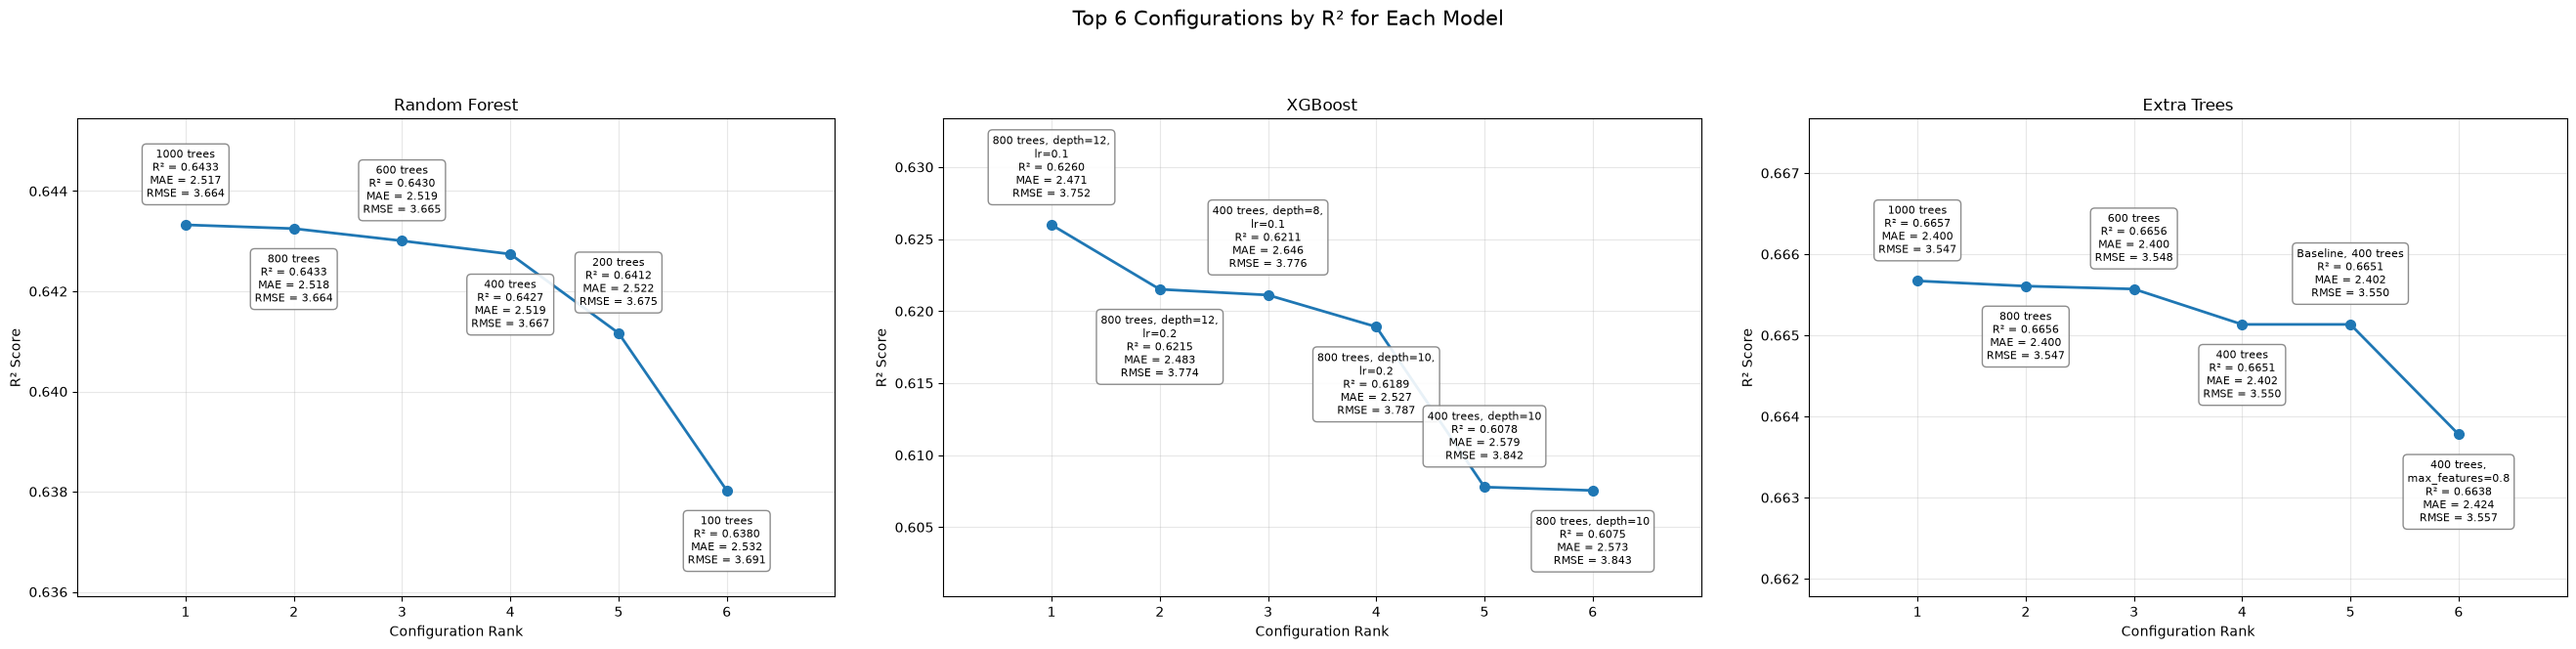

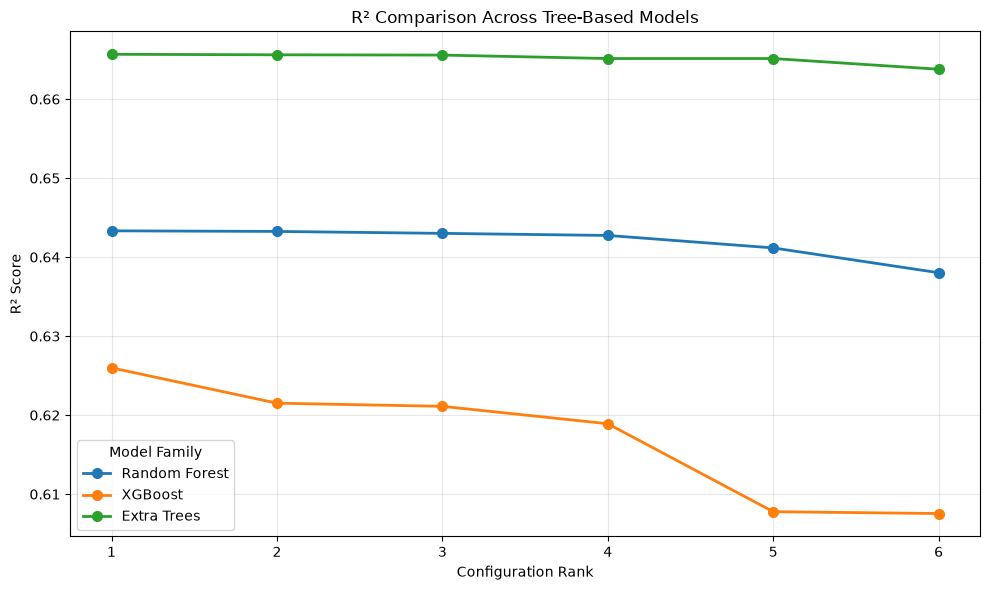

In [40]:
plotData=[]
for model, data in model_results.items():
    plotData.append([model,data.head(6)])

import matplotlib.pyplot as plt
import textwrap

fig, axes = plt.subplots(
    1, len(plotData),
    figsize=(9 * len(plotData), 7),
    squeeze=False
)

for i, (model, data) in enumerate(plotData):
    ax = axes[0][i]
    data = data.sort_values("R2", ascending=False).reset_index(drop=True)

    x = list(range(1, len(data) + 1))
    y = data["R2"].tolist()

    ax.plot(x, y, marker="o", markersize=7, linewidth=2)

    for j, row in data.iterrows():
        metadata = (
            f'{textwrap.fill(str(row["Model"]), width=22)}\n'
            f'R² = {row["R2"]:.4f}\n'
            f'MAE = {row["MAE"]:.3f}\n'
            f'RMSE = {row["RMSE"]:.3f}'
        )

        ax.annotate(
            metadata,
            (j + 1, row["R2"]),
            xytext=(0, 18 if j % 2 == 0 else -18),
            textcoords="offset points",
            ha="center",
            va="bottom" if j % 2 == 0 else "top",
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="gray", alpha=0.9),
            annotation_clip=False
        )

    y_min, y_max = min(y), max(y)
    y_range = max(y_max - y_min, 0.02)

    ax.set_xlim(0, len(data) + 1)
    y_min, y_max = min(y), max(y)
    y_range = max(y_max - y_min, 0.005)

    ax.set_ylim(
        y_min - 0.4 * y_range,
        y_max + 0.4 * y_range
    )
    ax.set_title(model)
    ax.set_xlabel("Configuration Rank")
    ax.set_ylabel("R² Score")
    ax.set_xticks(x)
    ax.grid(alpha=0.3)

fig.suptitle("Top 6 Configurations by R² for Each Model", fontsize=15)
plt.tight_layout(pad=3)
plt.show()
# Combined comparison plot
fig, ax = plt.subplots(figsize=(10, 6))

for model, data in plotData:
    data = data.sort_values("R2", ascending=False).reset_index(drop=True)

    x = range(1, len(data) + 1)
    y = data["R2"]

    ax.plot(
        x, y,
        marker="o",
        markersize=7,
        linewidth=2,
        label=model
    )

ax.set_title("R² Comparison Across Tree-Based Models")
ax.set_xlabel("Configuration Rank")
ax.set_ylabel("R² Score")
ax.set_xticks(range(1, 7))
ax.grid(alpha=0.3)
ax.legend(title="Model Family")
plt.tight_layout()
plt.show()